# LAB 1 for CS4243: Textures and Materials
## Notebook 4 — Personal photos and controlled VLM defect analysis

> **Introduction.** This final notebook combines two open-ended studies. Part I
> develops Texture Passports for your own photographs. Part II evaluates a VLM
> such as ChatGPT on five held-out MVTec defects under three controlled levels
> of information. Preserve inputs, prompts, outputs, and limitations.


# Part I — Personal-photo investigation

## Before looking at predictions

Complete `personal_annotations.csv` first. Obtain two independent selections
of three to five DTD terms per photograph, remove EXIF metadata, and check that
no people, identifying documents, or precise locations are visible.


## Suggested investigation structure

1. Introduce the collection with all relevant information.
2. Apply the frozen material, defect, and DTD systems without adapting them to this new data.
3. Select revealing successes, failures, and intermediate response maps.
4. Test one focused question about illumination, scale, or viewpoint.
5. Produce one Texture Passport per image and explain/reason about the uncertainty.


In [18]:
import sys
from pathlib import Path

import joblib

ROOT = next(
    candidate
    for parent in (Path.cwd(), *Path.cwd().parents)
    for candidate in (parent, parent / "code")
    if (candidate / "manifests" / "personal_annotations.csv").is_file()
)
sys.path.insert(0, str(ROOT))
PERSONAL_MANIFEST = ROOT / "manifests" / "personal_annotations.csv"
MODEL_DIR = ROOT / "outputs" / "models"

print("manifest available:", PERSONAL_MANIFEST.exists())
print("model directory available:", MODEL_DIR.exists())

# Notebooks 2 and 3 save self-describing bundles here. Load whichever are
# available, while keeping this open-ended notebook usable before training.
task_ab_path = MODEL_DIR / "task_ab_models.joblib"
task_c_path = MODEL_DIR / "task_c_attribute_model.joblib"
task_ab_bundle = joblib.load(task_ab_path) if task_ab_path.exists() else None
task_c_bundle = joblib.load(task_c_path) if task_c_path.exists() else None

if task_ab_bundle is None or task_c_bundle is None:
    print("Run Notebooks 2 and 3 first to create any missing model bundles.")
else:
    material_model = task_ab_bundle["material_classifier"]
    normal_models = task_ab_bundle["normal_models"]
    attribute_model = task_c_bundle["attribute_classifier"]
    feature_config = task_ab_bundle["feature_config"]
    normality_config = task_ab_bundle["normality_config"]
    attribute_config = task_c_bundle["feature_config"]
    attributes = task_c_bundle["attributes"]
    print("Loaded Task A/B keys:", sorted(task_ab_bundle))
    print("Loaded Task C keys:", sorted(task_c_bundle))

manifest available: True
model directory available: True
Loaded Task A/B keys: ['feature_config', 'image_size', 'material_classifier', 'materials', 'normal_models', 'normality_config', 'validation_selected_threshold']
Loaded Task C keys: ['attribute_classifier', 'attributes', 'feature_config', 'image_size']


## Personal-photo analysis workspace

The cell below applies the frozen Task A/B and Task C bundles to every personal
photo. Task B is routed by the **predicted material** in each passport; a separate
recorded-material diagnostic measures the effect of routing errors. No personal
photo is used to fit a model or select a threshold.

Each passport contains the source image, anomaly heatmap, predicted mask,
material confidence, five ranked DTD scores, a visual/evidence description and
an uncertainty statement. Maps are computed at the saved 64 x 64 resolution;
heatmap colour scales vary by image. Scores are not calibrated defect probabilities.

Outputs are saved to `student_files/personal_photo_analysis/`: `index.html`
contains all 15 passports, `passports.json` and `predictions.csv` contain the
results, and `maps/` preserves numeric maps and binary masks. Figures compare
confidence with anomaly response, human/model attribute overlap, and the
observational association between highlights/reflections and anomaly scores.

The supplied `bumpy` term completes carpet1 annotator 1 and both tile1 annotation
sets. Annotation timing and independence remain the manifest's declarations.
Unsupported full-DTD terms are retained and vocabulary coverage is reported.


### Personal-photo results: 15 passports
Material matches: **4/15**. Scores and thresholds are frozen; annotations were not used for fitting.

| Photo | Recorded material | Predicted material | Confidence | Anomaly score | Flagged interior |
| --- | --- | --- | --- | --- | --- |
| carpet1 | carpet | tile | 1.000 | 2.263 | 0.0% |
| carpet2 | carpet | tile | 1.000 | 5.542 | 13.1% |
| carpet3 | carpet | wood | 1.000 | 8.890 | 7.1% |
| carpet4 | carpet | wood | 0.971 | 11.403 | 40.4% |
| carpet5 | carpet | grid | 0.998 | 1.342 | 0.0% |
| tile1 | tile | grid | 0.521 | 1.567 | 0.0% |
| tile2 | tile | wood | 0.928 | 37.940 | 21.7% |
| tile3 | tile | wood | 1.000 | 11.187 | 28.6% |
| tile4 | tile | wood | 0.996 | 22.905 | 45.5% |
| wood1 | wood | leather | 0.622 | 118.533 | 100.0% |
| wood2 | wood | wood | 0.999 | 11.877 | 41.7% |
| wood3 | wood | tile | 1.000 | 2.487 | 0.0% |
| wood4 | wood | wood | 0.918 | 4.333 | 4.0% |
| wood5 | wood | wood | 0.996 | 7.851 | 24.9% |
| wood6 | wood | wood | 0.993 | 3.412 | 1.8% |

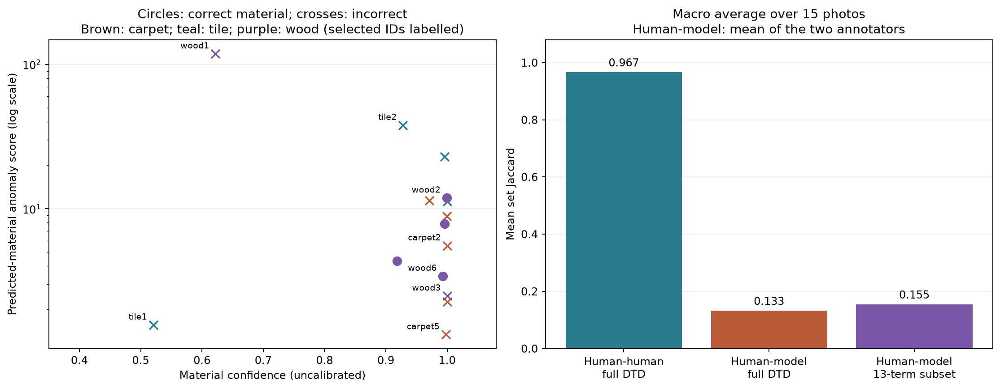

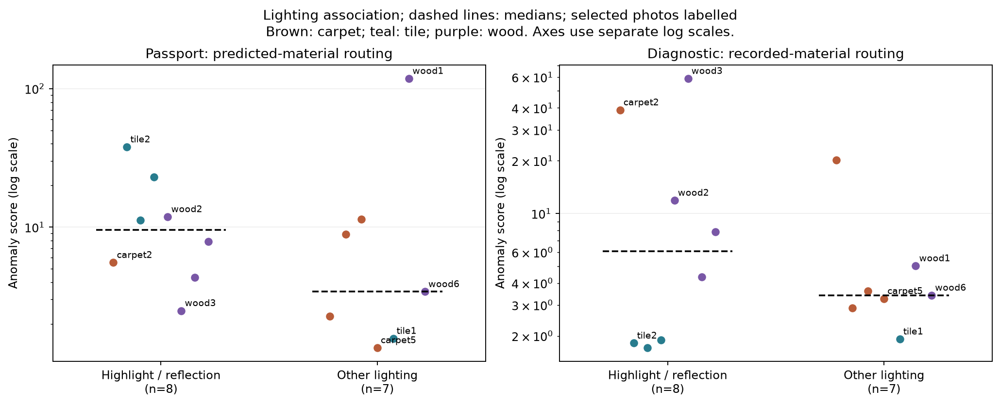

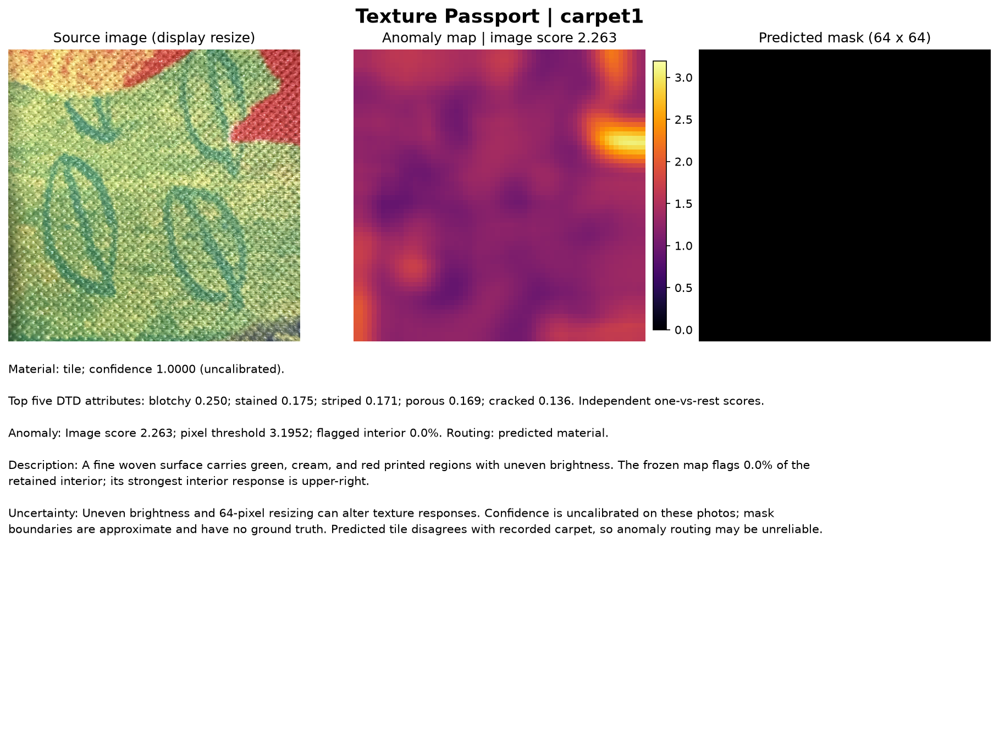

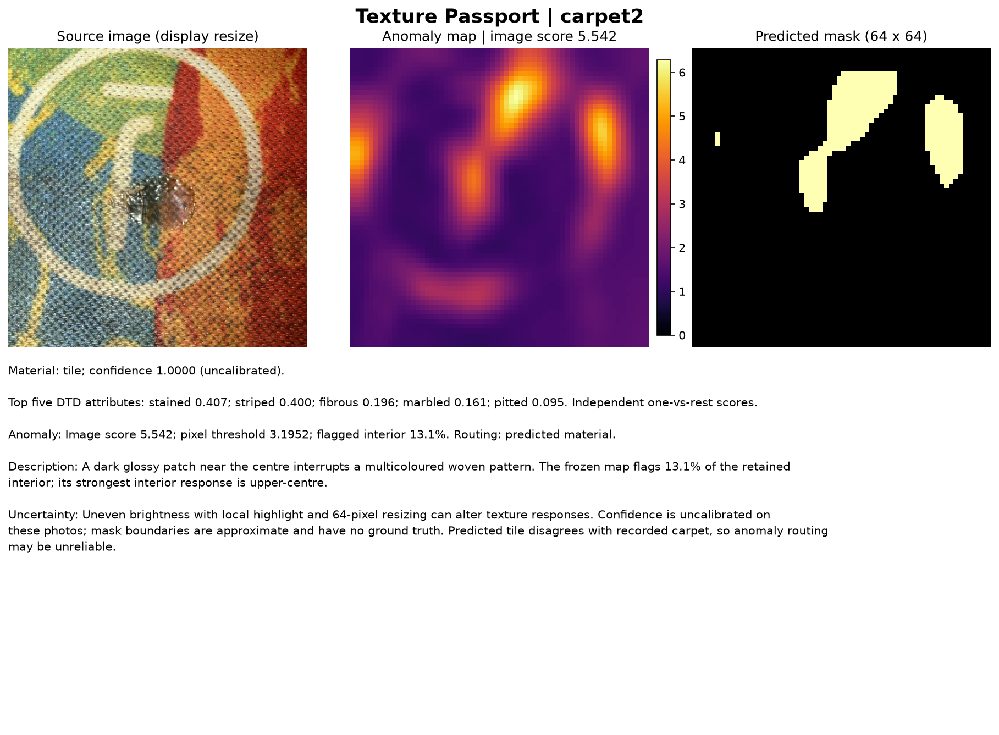

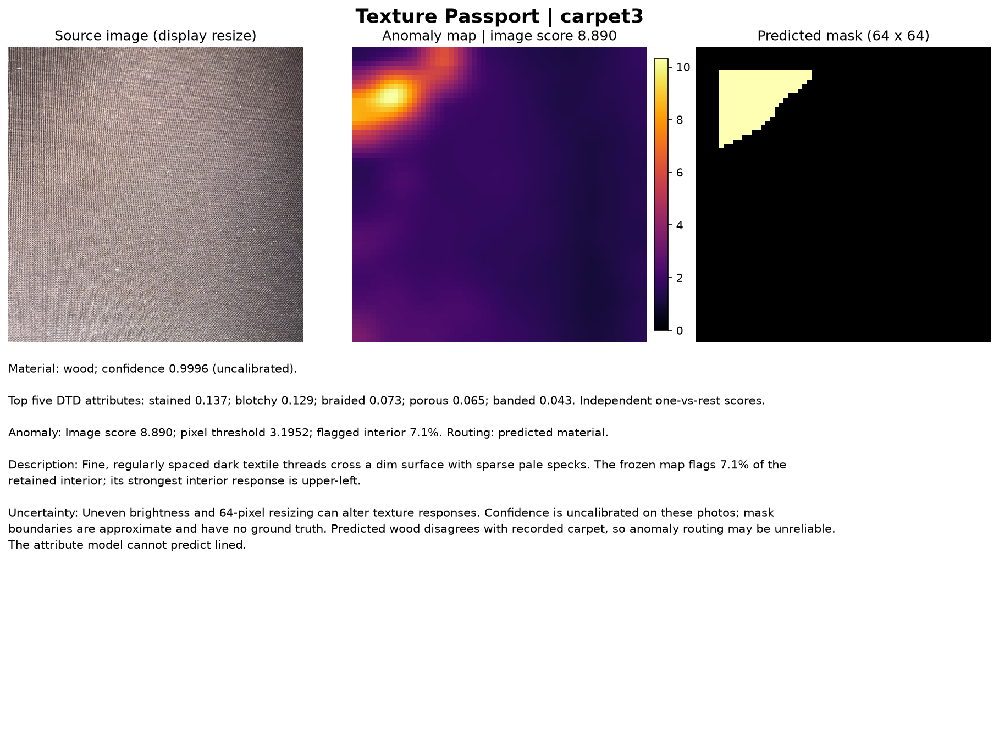

...

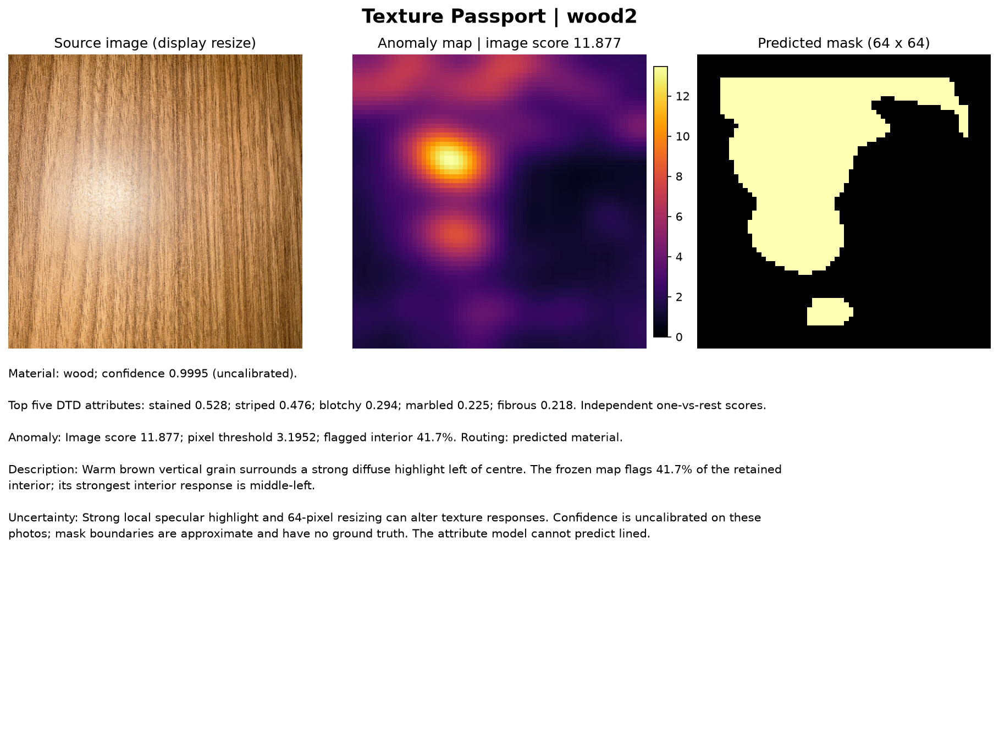

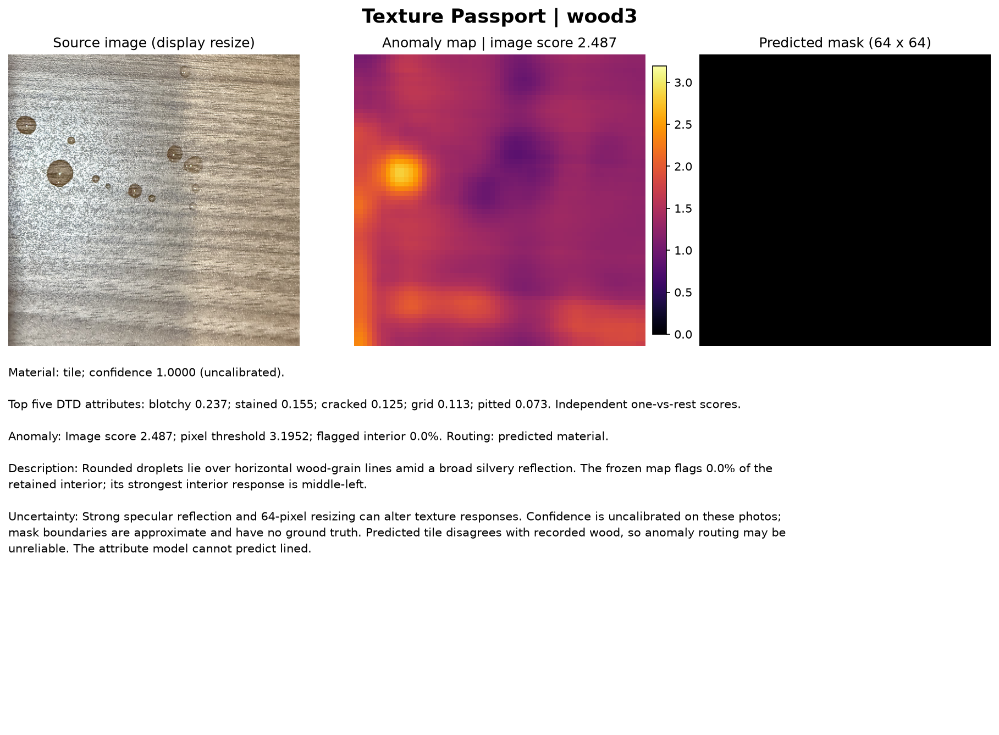

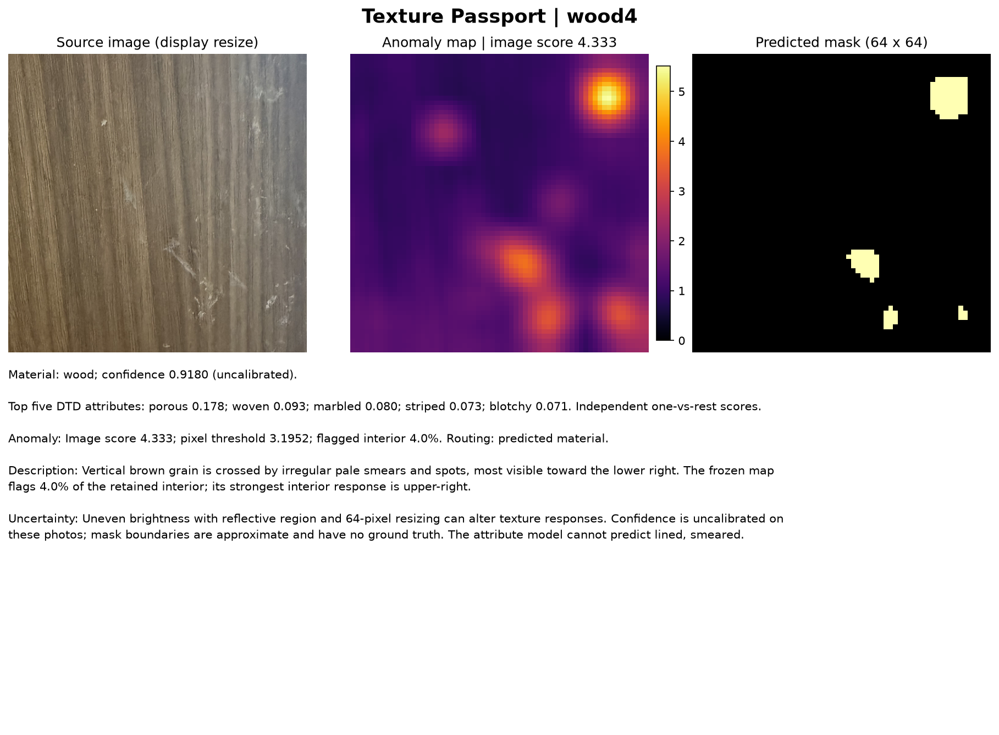

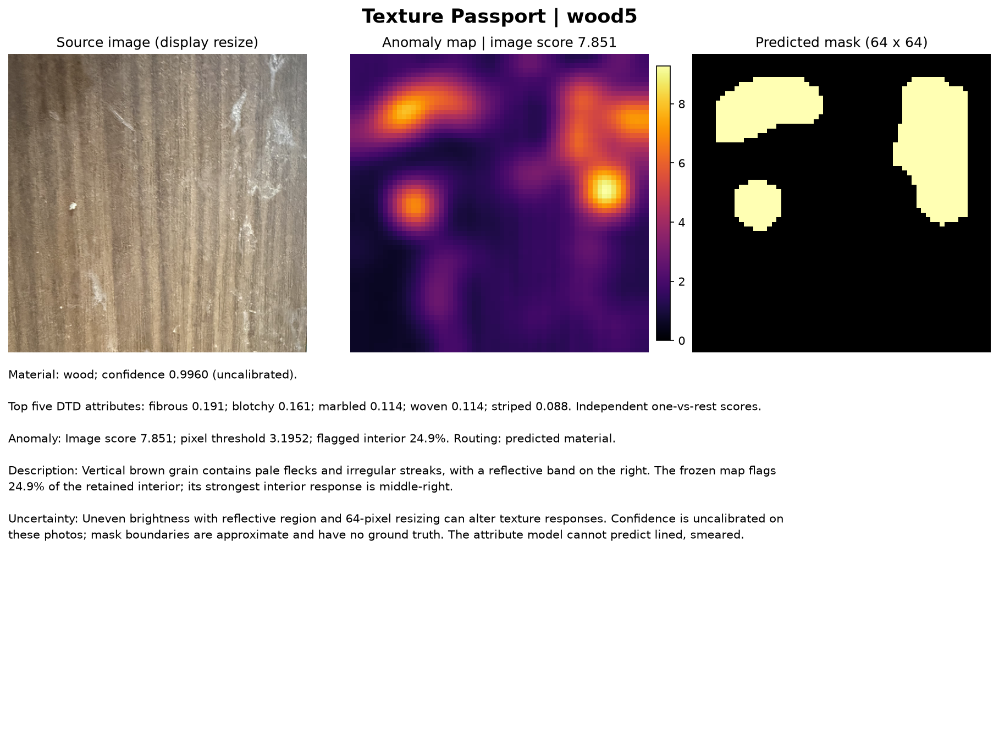

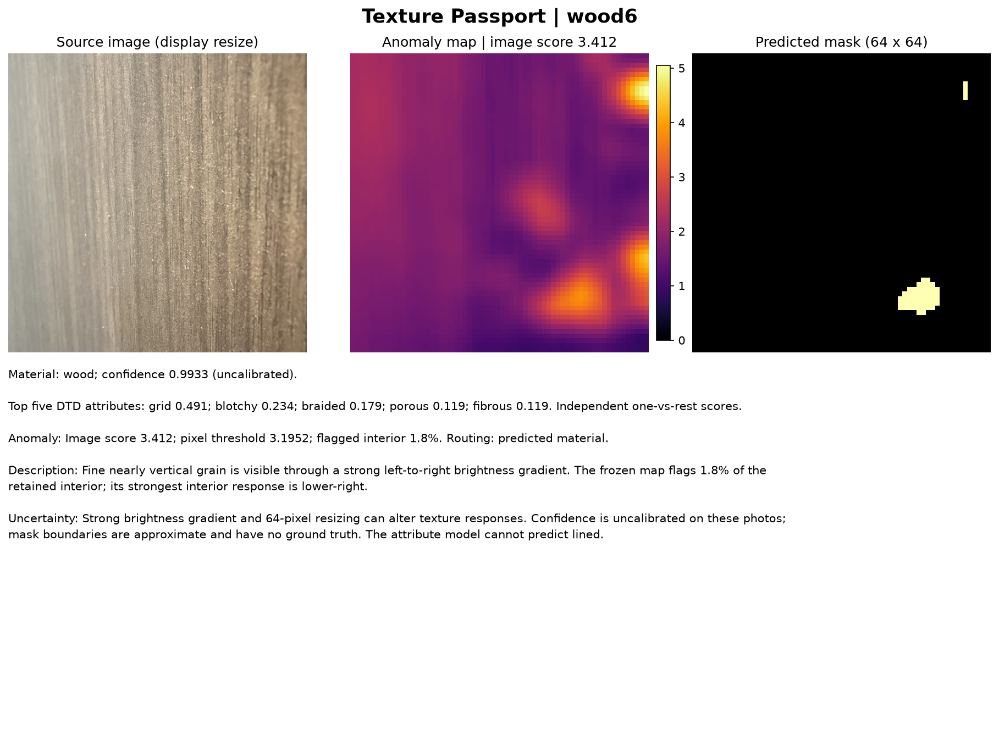

Saved 15 passports, raw maps/masks, CSV/JSON results, analysis figures and index.html to c:\Users\Matthew\Desktop\Y4S1\CS4243 Lab 1\code\student_files\personal_photo_analysis


In [19]:
# Frozen personal-photo inference: no fitting or threshold selection occurs here. [AI-CODE] [AI-DESIGN] [HUMAN-CHECK]
import csv
import hashlib
import html
import json
import textwrap
from collections import Counter
from dataclasses import asdict

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from PIL import Image as PILImage
from IPython.display import Image as DisplayImage, Markdown, display

from texturelab.features import extract_local_features, global_pool
from texturelab.normality import predict_anomaly
from texturelab.supplied import load_image

PHOTO_DIR = ROOT / "student_files" / "personal_photo_analysis"
for directory in (PHOTO_DIR, PHOTO_DIR / "passports", PHOTO_DIR / "maps"):
    directory.mkdir(parents=True, exist_ok=True)


def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def term_set(value):
    return {term.strip().lower() for term in value.split(";") if term.strip()}


def jaccard(left, right):
    return len(left & right) / len(left | right) if left | right else float("nan")


def save_table(filename, rows):
    with (PHOTO_DIR / filename).open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def show_photo_table(rows, columns):
    clean = lambda value: str(value).replace("|", r"\|").replace("\n", " ")
    lines = ["| " + " | ".join(label for _, label in columns) + " |",
             "| " + " | ".join("---" for _ in columns) + " |"]
    lines += ["| " + " | ".join(clean(row[key]) for key, _ in columns) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


frozen_hashes = {path.name: sha256(path) for path in (task_ab_path, task_c_path)}
manifest_hash = sha256(PERSONAL_MANIFEST)
with PERSONAL_MANIFEST.open(newline="", encoding="utf-8") as handle:
    photo_rows = list(csv.DictReader(handle))
assert len(photo_rows) >= 15, "An individual submission needs at least 15 photos."
assert len({row["material"] for row in photo_rows}) >= 3
photo_paths = [(PERSONAL_MANIFEST.parent / row["path"]).resolve() for row in photo_rows]
assert len(photo_paths) == len(set(photo_paths))
assert len({path.stem for path in photo_paths}) == len(photo_paths), "Use unique image IDs."
vocabulary = set(attributes)
assert len(vocabulary) == len(attributes) >= 5
assert list(attribute_model.attribute_names_) == list(attributes)
assert set(material_model.classes_) <= set(normal_models)

# Validate the two supplied annotations before generating the passport outputs.
# Additional full-DTD terms are retained; they are not silently mapped to the 13 trained terms.
annotation_audit = []
for row, path in zip(photo_rows, photo_paths):
    assert path.is_file(), str(path)
    assert row["split"] == "personal"
    assert row["annotation_completed_before_inference"].strip().lower() == "yes"
    assert row["exif_removed"].strip().lower() == "yes"
    with PILImage.open(path) as source:
        assert not source.getexif(), f"Remove EXIF metadata from {path.name}."
        original_size = source.size
    first, second = (term_set(row[key]) for key in ("annotator_1_terms", "annotator_2_terms"))
    assert 3 <= len(first) <= 5 and 3 <= len(second) <= 5, f"Need 3-5 terms per annotator: {path.name}"
    annotation_audit.append({
        "photo_id": path.stem, "original_width": original_size[0], "original_height": original_size[1],
        "source_sha256": sha256(path), "annotator_1_count": len(first), "annotator_2_count": len(second),
        "unsupported_terms": ";".join(sorted((first | second) - vocabulary)),
        "human_human_jaccard": jaccard(first, second),
    })

# Source-image observations, kept separate from the learned predictions and manifest defect labels.
visual_notes = {
    "carpet1": "A fine woven surface carries green, cream, and red printed regions with uneven brightness.",
    "carpet2": "A dark glossy patch near the centre interrupts a multicoloured woven pattern.",
    "carpet3": "Fine, regularly spaced dark textile threads cross a dim surface with sparse pale specks.",
    "carpet4": "A dense grey fibrous surface shows scattered pale flecks and broad brightness variation.",
    "carpet5": "Thick beige fibres interlace in a regular basket-weave grid.",
    "tile1": "A finely mottled pale surface fades from bright at the bottom to dark at the top.",
    "tile2": "A pale ring and small pale spots lie on a mottled surface, with a strong highlight near the upper left.",
    "tile3": "Rounded droplets and a vertical wet-looking streak cross a pale mottled surface around a central reflection.",
    "tile4": "A smooth pale surface shows two broad highlights, a diagonal shaded band, and faint narrow marks.",
    "wood1": "Dark brown grain forms mostly vertical fine lines, with a dimmer lower region.",
    "wood2": "Warm brown vertical grain surrounds a strong diffuse highlight left of centre.",
    "wood3": "Rounded droplets lie over horizontal wood-grain lines amid a broad silvery reflection.",
    "wood4": "Vertical brown grain is crossed by irregular pale smears and spots, most visible toward the lower right.",
    "wood5": "Vertical brown grain contains pale flecks and irregular streaks, with a reflective band on the right.",
    "wood6": "Fine nearly vertical grain is visible through a strong left-to-right brightness gradient.",
}

passports, photo_arrays = [], {}
ab_size, c_size = tuple(task_ab_bundle["image_size"]), tuple(task_c_bundle["image_size"])
border = normality_config.ignore_border
for row, path in zip(photo_rows, photo_paths):
    image_ab = load_image(str(path), ab_size)
    fmap, feature_names = extract_local_features(image_ab, feature_config)
    descriptor = global_pool(fmap)[None, :]
    assert descriptor.shape[1] == material_model.n_features_in_
    probabilities = material_model.predict_proba(descriptor)[0]
    assert np.isfinite(probabilities).all() and np.isclose(probabilities.sum(), 1)
    assert np.all((probabilities >= 0) & (probabilities <= 1))
    winner = int(np.argmax(probabilities))
    predicted_material = str(material_model.classes_[winner])

    # Use the saved Task C configuration and size, even if they differ from A/B.
    if c_size == ab_size and attribute_config == feature_config:
        attribute_map = fmap
    else:
        attribute_map, _ = extract_local_features(load_image(str(path), c_size), attribute_config)
    attribute_descriptor = global_pool(attribute_map)[None, :]
    assert attribute_descriptor.shape[1] == attribute_model.n_features_in_
    attribute_scores = attribute_model.predict_proba(attribute_descriptor)[0]
    assert len(attribute_scores) == len(attributes) and np.isfinite(attribute_scores).all()
    assert np.all((attribute_scores >= 0) & (attribute_scores <= 1))
    ranked = np.argsort(-attribute_scores, kind="stable")[:5]
    top_five = [{"term": str(attributes[i]), "score": float(attribute_scores[i])} for i in ranked]

    # End-to-end passports route Task B through the PREDICTED material.
    normal_model = normal_models[predicted_material]
    assert fmap.shape[-1] == len(normal_model.mean)
    assert normal_model.feature_names is None or feature_names == normal_model.feature_names
    score_map, image_score, mask = predict_anomaly(fmap, normal_model, normality_config)
    interior = np.zeros(mask.shape, dtype=bool)
    if border:
        interior[border:-border, border:-border] = True
    else:
        interior[:] = True
    assert score_map.shape == mask.shape == image_ab.shape[:2]
    assert np.isfinite(score_map).all() and mask.dtype == np.bool_
    assert np.array_equal(mask, (score_map >= normal_model.threshold) & interior)
    assert np.isclose(image_score, np.percentile(score_map[interior], normality_config.image_percentile))
    coverage = float(mask.sum() / interior.sum())

    # A separate diagnostic isolates routing errors; it never replaces the passport output.
    declared_score_map, declared_score, declared_mask = predict_anomaly(
        fmap, normal_models[row["material"]], normality_config)
    first, second = (term_set(row[key]) for key in ("annotator_1_terms", "annotator_2_terms"))
    predicted_terms = {item["term"] for item in top_five}
    hm_full = [jaccard(terms, predicted_terms) for terms in (first, second)]
    hm_supported = [jaccard(terms & vocabulary, predicted_terms) for terms in (first, second)]
    peak_y, peak_x = np.unravel_index(np.argmax(np.where(interior, score_map, -np.inf)), score_map.shape)
    location = ("upper", "middle", "lower")[min(2, 3 * peak_y // mask.shape[0])] + "-" + (
        "left", "centre", "right")[min(2, 3 * peak_x // mask.shape[1])]
    evidence = (f"The frozen map flags {coverage:.1%} of the retained interior; "
                f"its strongest interior response is {location}.")
    description = visual_notes.get(path.stem, f"Recorded acquisition: {row['viewpoint']}, {row['scale']}.") + " " + evidence
    uncertainty = (f"{row['illumination'].capitalize()} and 64-pixel resizing can alter texture responses. "
                   "Confidence is uncalibrated on these photos; mask boundaries are approximate and have no ground truth.")
    if predicted_material != row["material"]:
        uncertainty += f" Predicted {predicted_material} disagrees with recorded {row['material']}, so anomaly routing may be unreliable."
    unsupported = sorted((first | second) - vocabulary)
    if unsupported:
        uncertainty += " The attribute model cannot predict " + ", ".join(unsupported) + "."
    record = {
        "photo_id": path.stem, "source_path": row["path"], "recorded_material": row["material"],
        "recorded_defect": row["defect_type"], "viewpoint": row["viewpoint"], "scale": row["scale"],
        "illumination": row["illumination"], "predicted_material": predicted_material,
        "material_confidence": float(probabilities[winner]),
        "material_correct": predicted_material == row["material"],
        "material_probabilities": dict(zip(map(str, material_model.classes_), map(float, probabilities))),
        "top_attributes": top_five, "attribute_scores": dict(zip(map(str, attributes), map(float, attribute_scores))),
        "anomaly_score": image_score, "mask_threshold": float(normal_model.threshold),
        "mask_fraction_interior": coverage, "mask_fraction_full_image": float(mask.mean()),
        "recorded_material_anomaly_score": declared_score,
        "recorded_material_mask_fraction_interior": float(declared_mask.sum() / interior.sum()),
        "human_human_jaccard": jaccard(first, second),
        "human_model_jaccard_full": float(np.mean(hm_full)),
        "human_model_jaccard_supported": float(np.mean(hm_supported)),
        "human_supported_term_fraction": sum(len(t & vocabulary) for t in (first, second)) / (len(first) + len(second)),
        "annotator_1_terms": sorted(first), "annotator_2_terms": sorted(second),
        "unsupported_terms": unsupported, "description": description, "uncertainty": uncertainty,
        "passport_path": f"passports/{path.stem}.png", "map_path": f"maps/{path.stem}.npz",
    }
    passports.append(record)
    photo_arrays[path.stem] = (load_image(str(path), (512, 512)), score_map, mask)
    np.savez_compressed(PHOTO_DIR / record["map_path"], score_map=score_map, predicted_mask=mask,
                        image_score=np.float64(image_score), threshold=np.float64(normal_model.threshold),
                        recorded_material_score_map=declared_score_map, recorded_material_mask=declared_mask)
    PILImage.fromarray(mask.astype(np.uint8) * 255).save(PHOTO_DIR / "maps" / f"{path.stem}_mask.png")

# Render one complete passport per photo. Colour bars are per image; compare numeric scores.
for record in passports:
    source, score_map, mask = photo_arrays[record["photo_id"]]
    fig = plt.figure(figsize=(12, 8.8), layout="constrained")
    grid = fig.add_gridspec(2, 3, height_ratios=(1, 1.15))
    axes = [fig.add_subplot(grid[0, i]) for i in range(3)]
    axes[0].imshow(source)
    axes[0].set_title("Source image (display resize)")
    heat = axes[1].imshow(score_map, cmap="inferno", vmin=0,
                          vmax=max(float(score_map.max()), record["mask_threshold"]))
    axes[1].set_title(f"Anomaly map | image score {record['anomaly_score']:.3f}")
    fig.colorbar(heat, ax=axes[1], fraction=0.046, pad=0.025)
    axes[2].imshow(mask, cmap=ListedColormap(["black", "#ffffb3"]), vmin=0, vmax=1, interpolation="nearest")
    axes[2].set_title("Predicted mask (64 x 64)")
    for ax in axes:
        ax.set_axis_off()
    text_ax = fig.add_subplot(grid[1, :])
    text_ax.set_axis_off()
    attribute_text = "; ".join(f"{item['term']} {item['score']:.3f}" for item in record["top_attributes"])
    fields = [
        ("Material", f"{record['predicted_material']}; confidence {record['material_confidence']:.4f} (uncalibrated)."),
        ("Top five DTD attributes", attribute_text + ". Independent one-vs-rest scores."),
        ("Anomaly", f"Image score {record['anomaly_score']:.3f}; pixel threshold {record['mask_threshold']:.4f}; "
                    f"flagged interior {record['mask_fraction_interior']:.1%}. Routing: predicted material."),
        ("Description", record["description"]),
        ("Uncertainty", record["uncertainty"]),
    ]
    paragraphs = [textwrap.fill(f"{label}: {value}", width=137) for label, value in fields]
    text_ax.text(0, 1, "\n\n".join(paragraphs), va="top", fontsize=10, linespacing=1.4)
    fig.suptitle(f"Texture Passport | {record['photo_id']}", fontsize=17, fontweight="bold")
    fig.savefig(PHOTO_DIR / record["passport_path"], dpi=150, bbox_inches="tight")
    plt.close(fig)

flat_rows = [{**{key: value for key, value in record.items() if not isinstance(value, (dict, list))},
              "top_five_attributes": ";".join(f"{item['term']}:{item['score']:.6f}" for item in record["top_attributes"]),
              "unsupported_terms": ";".join(record["unsupported_terms"])} for record in passports]
save_table("predictions.csv", flat_rows)
save_table("annotation_audit.csv", annotation_audit)
(PHOTO_DIR / "passports.json").write_text(json.dumps(passports, indent=2, allow_nan=False) + "\n", encoding="utf-8")
cards = "\n".join(f'<article id="{html.escape(r["photo_id"])}"><a href="{r["passport_path"]}">'
                  f'<img src="{r["passport_path"]}" alt="Texture passport for {html.escape(r["photo_id"])}"></a></article>'
                  for r in passports)
(PHOTO_DIR / "index.html").write_text(
    '<!doctype html><html lang="en"><meta charset="utf-8"><title>Personal Texture Passports</title>'
    '<style>body{max-width:1200px;margin:2em auto;font:16px sans-serif;background:#eee}img{width:100%}'
    'article{margin:2em 0;background:white;break-inside:avoid}@media print{article{break-after:page}}</style>'
    '<h1>Personal Texture Passports</h1><p>15 frozen-model predictions. Heatmap colour scales vary per image. '
    'Masks use the saved validation threshold and exclude the 5-pixel border. No ground-truth masks are used.</p>'
    '<p><a href="predictions.csv">Prediction table</a> | <a href="passports.json">Full scores and descriptions</a></p>'
    + cards + '</html>', encoding="utf-8")

# Confidence versus anomaly response, and annotation agreement with explicit vocabulary coverage.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
colours = {"carpet": "#b85c38", "tile": "#287c8e", "wood": "#7957a6"}
labelled_cases = {"carpet2", "carpet5", "tile1", "tile2", "wood1", "wood2", "wood3", "wood6"}
for record in passports:
    axes[0].scatter(record["material_confidence"], record["anomaly_score"],
                    color=colours.get(record["recorded_material"], "grey"),
                    marker="o" if record["material_correct"] else "x", s=65)
    if record["photo_id"] in labelled_cases:
        axes[0].annotate(record["photo_id"], (record["material_confidence"], record["anomaly_score"]),
                         xytext=(-6, 5), textcoords="offset points", fontsize=8, ha="right")
axes[0].set(xlabel="Material confidence (uncalibrated)", ylabel="Predicted-material anomaly score (log scale)",
            yscale="log", xlim=(0.35, 1.08), title="Circles: correct material; crosses: incorrect\nBrown: carpet; teal: tile; purple: wood (selected IDs labelled)")
metrics = ["human_human_jaccard", "human_model_jaccard_full", "human_model_jaccard_supported"]
means = [float(np.mean([r[key] for r in passports])) for key in metrics]
bars = axes[1].bar(["Human-human\nfull DTD", "Human-model\nfull DTD", "Human-model\n13-term subset"], means,
                   color=["#287c8e", "#b85c38", "#7957a6"])
for bar, mean in zip(bars, means):
    axes[1].text(bar.get_x() + bar.get_width()/2, mean + 0.02, f"{mean:.3f}", ha="center")
axes[1].set(ylim=(0, 1.08), ylabel="Mean set Jaccard", title="Macro average over 15 photos\nHuman-model: mean of the two annotators")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
fig.savefig(PHOTO_DIR / "confidence_and_attributes.png", dpi=170, bbox_inches="tight")
plt.close(fig)

# Focused descriptive question: do reflective/highlight scenes score higher?
# These are not matched interventions; material, scale, viewpoint and defects vary together.
lighting_summary = []
lighting_groups = {
    "Highlight / reflection": [r for r in passports if any(term in r["illumination"].lower()
                                for term in ("highlight", "specular", "reflective"))],
    "Other lighting": [r for r in passports if not any(term in r["illumination"].lower()
                       for term in ("highlight", "specular", "reflective"))],
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
for axis, metric, title in zip(axes, ("anomaly_score", "recorded_material_anomaly_score"),
                             ("Passport: predicted-material routing", "Diagnostic: recorded-material routing")):
    for position, (group, records) in enumerate(lighting_groups.items()):
        values = [r[metric] for r in records]
        for offset, record in zip(np.linspace(-0.22, 0.22, len(records)), records):
            axis.scatter(position + offset, record[metric], color=colours[record["recorded_material"]])
            if record["photo_id"] in labelled_cases:
                axis.annotate(record["photo_id"], (position + offset, record[metric]),
                              xytext=(3, 4), textcoords="offset points", fontsize=8)
        median = float(np.median(values))
        axis.hlines(median, position - 0.3, position + 0.3, color="black", linestyle="--")
        lighting_summary.append({"group": group, "routing": metric, "n": len(records),
                                 "median_score": median, "mean_score": float(np.mean(values))})
    axis.set_xticks(range(len(lighting_groups)), [f"{name}\n(n={len(records)})" for name, records in lighting_groups.items()])
    axis.set(title=title, ylabel="Anomaly score (log scale)", yscale="log", xlim=(-0.5, 1.5))
    axis.grid(axis="y", alpha=0.2)
fig.suptitle("Lighting association; dashed lines: medians; selected photos labelled\nBrown: carpet; teal: tile; purple: wood. Axes use separate log scales.")
fig.savefig(PHOTO_DIR / "lighting_and_routing.png", dpi=170, bbox_inches="tight")
plt.close(fig)
save_table("lighting_summary.csv", lighting_summary)

material_summary = []
for material in sorted({r["recorded_material"] for r in passports}):
    records = [r for r in passports if r["recorded_material"] == material]
    material_summary.append({"material": material, "n": len(records),
        "correct": sum(r["material_correct"] for r in records),
        "mean_confidence": float(np.mean([r["material_confidence"] for r in records])),
        "median_anomaly_score": float(np.median([r["anomaly_score"] for r in records]))})
save_table("material_summary.csv", material_summary)
summary = {
    "n_photos": len(passports), "recorded_material_counts": dict(Counter(r["material"] for r in photo_rows)),
    "material_correct": sum(r["material_correct"] for r in passports),
    "material_accuracy": float(np.mean([r["material_correct"] for r in passports])),
    **dict(zip(metrics, means)),
    "human_exact_agreement_count": sum(r["human_human_jaccard"] == 1 for r in passports),
    "supported_annotation_terms": sum(len(set(r[k]) & vocabulary) for r in passports for k in ("annotator_1_terms", "annotator_2_terms")),
    "total_annotation_terms": sum(len(r[k]) for r in passports for k in ("annotator_1_terms", "annotator_2_terms")),
    "model_sha256": frozen_hashes, "manifest_sha256": manifest_hash,
    "ab_image_size": ab_size, "c_image_size": c_size, "feature_config": asdict(feature_config),
    "attribute_config": asdict(attribute_config), "normality_config": asdict(normality_config),
    "attribute_vocabulary": list(attributes),
    "routing": "Predicted material for passports; recorded material only for a separate diagnostic.",
    "mask_fraction_denominator": "Retained interior (54 x 54); full-image fraction exported separately.",
}
assert sha256(PERSONAL_MANIFEST) == manifest_hash
assert all(sha256(path) == frozen_hashes[path.name] for path in (task_ab_path, task_c_path))
(PHOTO_DIR / "analysis_metadata.json").write_text(json.dumps(summary, indent=2, allow_nan=False) + "\n", encoding="utf-8")

display(Markdown(f"### Personal-photo results: {len(passports)} passports\n"
                 f"Material matches: **{summary['material_correct']}/{len(passports)}**. "
                 "Scores and thresholds are frozen; annotations were not used for fitting."))
show_photo_table([{"id": r["photo_id"], "recorded": r["recorded_material"], "predicted": r["predicted_material"],
                  "confidence": f"{r['material_confidence']:.3f}", "score": f"{r['anomaly_score']:.3f}",
                  "coverage": f"{r['mask_fraction_interior']:.1%}"} for r in passports],
                 [("id", "Photo"), ("recorded", "Recorded material"), ("predicted", "Predicted material"),
                  ("confidence", "Confidence"), ("score", "Anomaly score"), ("coverage", "Flagged interior")])
display(DisplayImage(filename=str(PHOTO_DIR / "confidence_and_attributes.png")))
display(DisplayImage(filename=str(PHOTO_DIR / "lighting_and_routing.png")))
for record in passports:
    display(DisplayImage(filename=str(PHOTO_DIR / record["passport_path"])))
print(f"Saved {len(passports)} passports, raw maps/masks, CSV/JSON results, analysis figures and index.html to {PHOTO_DIR}")


# Part II — Task D: VLM defect classification

This task tests whether a VLM can identify and name surface defects under three
levels of supplied information. The five queries come from held-out MVTec test.
Do not expose the answer key while collecting predictions.


## Experimental conditions

| Level | Information supplied | Question being tested |
|---|---|---|
| **D1 — Generic zero-shot** | Test image and a generic instruction such as “Find any defect in this surface.” | Can the model discover that something is abnormal without domain guidance? |
| **D2 — Named-defect zero-shot** | Test image, material name, and allowed defect names with short verbal definitions; no defect images | Does domain vocabulary help the model recognize and name defects? |
| **D3 — Example-conditioned** | D2 information plus the fixed labelled support set from public validation | Can visual examples transfer a defect concept to new images? |

Use the same VLM, model version, decoding settings, query order, and output
format for all three conditions. Start a fresh conversation for each query and
condition so earlier answers do not leak information.


## 1. Load the five held-out queries

The public query manifest contains paths, material names, and allowed labels.
True labels are stored separately in the staff solution folder.


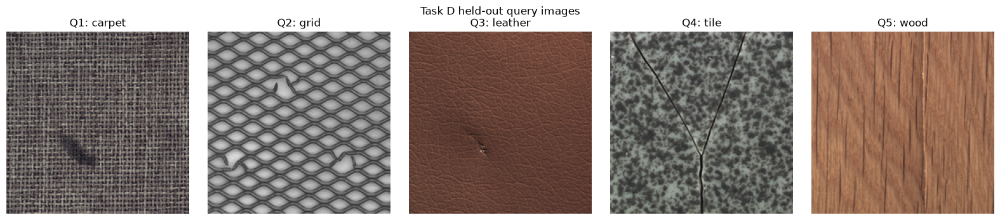

In [20]:
import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt

# Locate code/ from the workspace root, code/, or notebooks/.
ROOT = next(
    candidate
    for parent in (Path.cwd(), *Path.cwd().parents)
    for candidate in (parent, parent / "code")
    if (candidate / "manifests" / "task_d_queries.csv").is_file()
)
sys.path.insert(0, str(ROOT))

from texturelab.supplied import load_image

MANIFEST_DIR = ROOT / "manifests"

with (MANIFEST_DIR / "task_d_queries.csv").open(newline="", encoding="utf8") as handle:
    queries = list(csv.DictReader(handle))

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, query in zip(axes, queries):
    path = (MANIFEST_DIR / query["path"]).resolve()
    ax.imshow(load_image(str(path), (220, 220)))
    ax.set_title(f"{query['id']}: {query['material']}")
    ax.axis("off")
fig.suptitle("Task D held-out query images")
fig.tight_layout()
plt.show()

## 2. D1 — generic zero-shot

Attach one query image and use only a generic prompt. Ask for a binary defect
decision, a short defect name if abnormal, confidence from 0 to 100, and one
sentence of visible evidence. Do not mention the material or allowed labels.

Suggested prompt:

> Inspect this surface image. Is anything visibly abnormal? Return JSON with
> `is_defective`, `defect_name`, `confidence`, and `evidence`.


## 3. D2 — named-defect zero-shot

Provide the material and its allowed defect names with the supplied short
definitions, but no labelled example images. Require exactly one allowed label
or `good`.


In [21]:
import json

definitions = json.loads(
    (MANIFEST_DIR / "task_d_definitions.json").read_text(encoding="utf8")
)
for query in queries:
    print()
    print(f"{query['id']} — {query['material']}")
    for name, definition in definitions[query["material"]].items():
        print(f"  {name}: {definition}")


Q1 — carpet
  color: A localized region has an abnormal colour or tone.
  cut: A sharp incision or sliced region interrupts the texture.
  hole: Material is missing in a compact hole-like region.
  metal_contamination: A metallic foreign object lies on the surface.
  thread: A foreign thread lies across the regular texture.

Q2 — grid
  bent: The regular grid lines are locally warped or displaced.
  broken: Part of the repeating grid is interrupted or missing.
  glue: A localized glue deposit changes the surface appearance.
  metal_contamination: A metallic foreign object lies on the surface.
  thread: A foreign thread lies across the regular texture.

Q3 — leather
  color: A localized region has an abnormal colour or tone.
  cut: A sharp incision or sliced region interrupts the texture.
  fold: The surface is creased or folded out of its normal plane.
  glue: A localized glue deposit changes the surface appearance.
  poke: A small puncture-like indentation or opening is visible.

Q4 

## 4. D3 — example-conditioned

Provide the same D2 text plus the fixed support images associated with the
query ID in `task_d_support.csv`. Each support image is labelled and comes only
from public validation. Do not add hand-selected examples or test images.

Ask the VLM to compare the query with all examples and return the same JSON
schema used in D1 and D2.


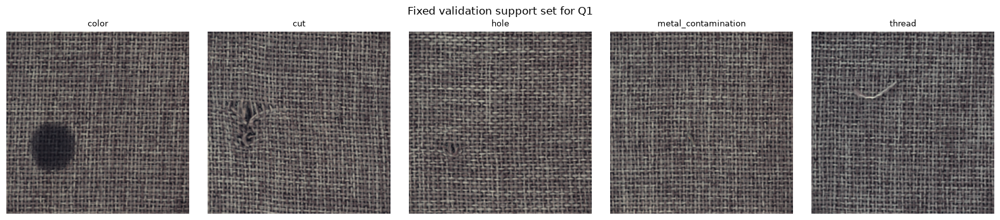

In [22]:
with (MANIFEST_DIR / "task_d_support.csv").open(newline="", encoding="utf8") as handle:
    support = list(csv.DictReader(handle))

# Visualise the fixed support set for the first query.
query_id = queries[0]["id"]
examples = [row for row in support if row["query_id"] == query_id]
fig, axes = plt.subplots(1, len(examples), figsize=(16, 3.5))
for ax, example in zip(axes, examples):
    path = (MANIFEST_DIR / example["path"]).resolve()
    ax.imshow(load_image(str(path), (200, 200)))
    ax.set_title(example["defect_name"], fontsize=9)
    ax.axis("off")
fig.suptitle(f"Fixed validation support set for {query_id}")
fig.tight_layout()
plt.show()

## 5. Record predictions before scoring

Create one row per query and condition with: query ID, condition, predicted
label, defective/not-defective decision, confidence, visible evidence, exact
prompt, model/version, and run date. Preserve the raw conversations or exported
screenshots as evidence. Only after all 15 responses are frozen should the
answer key be used to calculate accuracy.


## Compiled Task D prediction rows

**Model/version:** Gemini Flash 3.6. **Run date:** 6 October 2026. **Decoding settings:** unavailable (as recorded in the CSV). [AI-VISION] 

The 15 rows below were compiled from cell 17 and checked against the saved responses in `student_files/task_d/outputs/D1`, `D2`, and `D3`. The [prediction CSV](../student_files/task_d/task_d_predictions.csv) stores one row per query and condition, including the exact prompt documented in each condition's `JSONs.md`, the verbatim pasted JSON response, model/version, run date, and source references. The original responses above are preserved.

| Query | Material | Condition | Defective? | Predicted label | Confidence (0--100) | Visible evidence |
|---|---|---|---|---|---|---|
| Q1 | carpet | D1 | Yes | stain | 98 | There is a prominent dark smudge or stain visible on the lower-left section of the woven fabric surface. |
| Q2 | grid | D1 | Yes | bent wire | 98 | Multiple sections of the metal mesh grid are visibly broken, bent, and deformed out of their standard geometric pattern. |
| Q3 | leather | D1 | Yes | cut | 98 | There is a visible dark slash or cut with exposed light fiber material located in the lower-left quadrant of the textured brown surface. |
| Q4 | tile | D1 | Yes | crack | 100 | A prominent Y-shaped dark crack spans across the speckled surface of the material. |
| Q5 | wood | D1 | Yes | crack | 95 | A prominent vertical crack runs through the wood surface right of center. |
| Q1 | carpet | D2 | Yes | color | 95 | There is a localized dark brownish stain/discoloration in the lower-left section of the woven carpet texture. |
| Q2 | grid | D2 | Yes | broken | 98 | Multiple segments of the wire grid structure are severed and fractured, leaving broken ends interrupting the uniform lattice pattern. |
| Q3 | leather | D2 | Yes | cut | 95 | A sharp incision and slice interrupt the leather texture in the lower-left central quadrant. |
| Q4 | tile | D2 | Yes | crack | 100 | A clear, branching dark fracture line crosses the surface of the tile. |
| Q5 | wood | D2 | Yes | scratch | 95 | A long, continuous vertical line/abrasion is visible cutting through the wood grain pattern slightly to the right of center. |
| Q1 | carpet | D3 | Yes | color | 95 | There is a localized, dark discolored stain/patch near the lower-left section of the woven carpet texture. |
| Q2 | grid | D3 | Yes | bent | 98 | Multiple regular wire strands of the grid structure are locally warped and bent out of shape across the surface. |
| Q3 | leather | D3 | Yes | cut | 95 | A sharp incision and slice interrupt the leather texture in the lower-left central portion of the surface. |
| Q4 | tile | D3 | Yes | crack | 98 | A prominent dark, Y-shaped fracture line splits and crosses the tile surface. |
| Q5 | wood | D3 | No | good | 95 | The wood surface exhibits normal wood grain texture and vertical natural fissures without any color spots, holes, liquid stains, or abrasion scratches. |

All 15 responses contain the four requested fields. All D2/D3 predictions use an allowed defect label or `good`; D1 retains its free-form labels. This table records the predictions before answer-key scoring.


## Analysis ideas

- Compare D1 anomaly discovery with D2/D3 exact-label accuracy.
- Count answers that violate the allowed vocabulary.
- Plot confidence for correct and incorrect predictions by condition.
- Identify queries where definitions help but examples do not, and vice versa.
- Discuss prompt sensitivity, model updates, nondeterminism, and possible prior
  exposure to the public MVTec dataset.
- Do not claim that five images establish general VLM superiority; this is a
  controlled qualitative probe.


## 6. Analyse the frozen experiment

Run the cells below in order. They are independent of the personal-photo model
cells and read the completed prediction CSV. All 15 raw responses must exist
before the answer key is loaded. The original predictions are kept unchanged;
derived tables and figures are written to `student_files/task_d/analysis/`.

We compare **binary anomaly discovery** for all conditions and **exact-label
accuracy** for D2/D3. D1 permits free-form names, so its literal label matches are
shown only as a diagnostic; no synonyms are assigned retrospectively. D1 names
outside the supplied vocabulary are not protocol violations. Confidence is the
model's self-reported confidence in the decision and name, not a calibrated
probability. No repeated trials or prompt perturbations were collected.

In [23]:
#[AI-CODE] [HUMAN-CHECK]

import csv
import hashlib
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

ROOT = next(
    candidate
    for parent in (Path.cwd(), *Path.cwd().parents)
    for candidate in (parent, parent / "code")
    if (candidate / "manifests" / "task_d_queries.csv").is_file()
)
TASK_D_DIR = ROOT / "student_files" / "task_d"
ANALYSIS_DIR = TASK_D_DIR / "analysis"
LOG_PATH = TASK_D_DIR / "task_d_predictions.csv"
CONDITIONS = ("D1", "D2", "D3")


def read_csv(path):
    with path.open(newline="", encoding="utf-8") as handle:
        return list(csv.DictReader(handle))


def write_csv(name, rows):
    with (ANALYSIS_DIR / name).open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def show_table(rows, columns):
    def clean(value):
        return str(value).replace("|", r"\|").replace("\n", " ")
    header = "| " + " | ".join(label for _, label in columns) + " |"
    separator = "| " + " | ".join("---" for _ in columns) + " |"
    body = ["| " + " | ".join(clean(row[key]) for key, _ in columns) + " |" for row in rows]
    display(Markdown("\n".join([header, separator, *body])))


query_rows = read_csv(ROOT / "manifests" / "task_d_queries.csv")
query_by_id = {row["id"]: row for row in query_rows}
query_order = [row["id"] for row in query_rows]
assert len(query_order) == len(set(query_order)) == 5
prediction_rows = read_csv(LOG_PATH)
expected_pairs = {(qid, condition) for condition in CONDITIONS for qid in query_order}
pairs = [(row["query_id"], row["condition"]) for row in prediction_rows]
assert len(pairs) == 15 and set(pairs) == expected_pairs, "Need exactly 15 unique responses."
for row in prediction_rows:
    assert row["raw_response"].strip() and row["exact_prompt"].strip(), "Complete responses/prompts before scoring."
    raw = json.loads(row["raw_response"])
    assert row["is_defective"] in ("true", "false")
    assert type(raw["is_defective"]) is bool
    assert raw["is_defective"] == (row["is_defective"] == "true")
    assert raw["defect_name"] == row["predicted_label"]
    assert raw["evidence"] == row["evidence"]
    assert type(raw["confidence"]) in (int, float)
    confidence = float(row["confidence"])
    assert math.isfinite(confidence) and 0 <= confidence <= 100
    assert raw["confidence"] == confidence
    assert row["material"] == query_by_id[row["query_id"]]["material"]

# Load the answer key only after checking the complete frozen prediction set.
key_rows = read_csv(ROOT / "solution" / "task_d_answer_key.csv")
answer_by_id = {row["id"]: row for row in key_rows}
assert len(key_rows) == len(answer_by_id) == len(query_order)
assert set(answer_by_id) == set(query_order)
assert all(answer_by_id[qid]["material"] == query_by_id[qid]["material"] for qid in query_order)
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
log_hash = hashlib.sha256(LOG_PATH.read_bytes()).hexdigest()
metadata = sorted({(r["model"], r["model_version"], r["run_date"], r["decoding_settings"]) for r in prediction_rows})
show_table([dict(zip(("model", "version", "date", "settings"), values)) for values in metadata],
           [("model", "Recorded model"), ("version", "Version"), ("date", "Run date"), ("settings", "Decoding settings")])
print(f"Loaded {len(prediction_rows)} complete responses; prediction CSV SHA-256: {log_hash}")

| Recorded model | Version | Run date | Decoding settings |
| --- | --- | --- | --- |
| Gemini Flash | 3.6 | 2026-10-06 | unavailable |

Loaded 15 complete responses; prediction CSV SHA-256: b021417226035dfb38e3181e2dc1047d3b560d92e8798a93502023a69e57ac6e


### Detection, naming, and vocabulary compliance

Every query in the answer key is defective, binary accuracy therefore equals
observed defect sensitivity on these five images; specificity and false-positive
rate cannot be measured. Exact-label matching is case-sensitive and uses the
recorded label without renaming it. An out-of-vocabulary D2/D3 label remains in
the denominator and is counted as incorrect. D1 literal matches are diagnostic
because its prompt did not require these labels.

In [24]:
#[AI-CODE] [HUMAN-CHECK]

scored_rows = []
for row in prediction_rows:
    qid, condition = row["query_id"], row["condition"]
    truth = answer_by_id[qid]["true_defect"]
    predicted_defective = row["is_defective"] == "true"
    truth_defective = truth != "good"
    allowed = query_by_id[qid]["allowed_defects"].split(";") + ["good"]
    in_vocabulary = row["predicted_label"] in allowed
    scored_rows.append({
        "query_id": qid, "material": row["material"], "condition": condition,
        "true_label": truth, "true_is_defective": truth_defective,
        "predicted_label": row["predicted_label"], "is_defective": predicted_defective,
        "confidence": float(row["confidence"]), "evidence": row["evidence"],
        "binary_correct": predicted_defective == truth_defective,
        "exact_label_correct": row["predicted_label"] == truth,
        "outside_supplied_vocabulary": not in_vocabulary,
        "vocabulary_violation": condition in ("D2", "D3") and not in_vocabulary,
        "decision_label_consistent": predicted_defective == (row["predicted_label"] != "good"),
    })
scored_rows.sort(key=lambda r: (CONDITIONS.index(r["condition"]), query_order.index(r["query_id"])))
condition_summary = []
for condition in CONDITIONS:
    group = [r for r in scored_rows if r["condition"] == condition]
    n = len(group)
    detected = sum(r["binary_correct"] for r in group)
    named = sum(r["exact_label_correct"] for r in group)
    condition_summary.append({
        "condition": condition, "n": n,
        "binary_correct": detected, "binary_accuracy": detected / n,
        "exact_label_correct": named, "exact_label_accuracy": named / n,
        "exact_label_interpretation": "literal diagnostic only" if condition == "D1" else "task accuracy",
        "outside_supplied_vocabulary": sum(r["outside_supplied_vocabulary"] for r in group),
        "vocabulary_violations": "N/A (free-form)" if condition == "D1" else sum(r["vocabulary_violation"] for r in group),
        "decision_label_inconsistencies": sum(not r["decision_label_consistent"] for r in group),
        "mean_confidence": round(float(np.mean([r["confidence"] for r in group])), 2),
    })
write_csv("scored_predictions.csv", scored_rows)
write_csv("condition_summary.csv", condition_summary)
show_table(condition_summary, [("condition", "Condition"), ("n", "Queries"),
    ("binary_correct", "Binary correct"), ("binary_accuracy", "Binary accuracy"),
    ("exact_label_correct", "Exact names"), ("exact_label_accuracy", "Exact fraction"),
    ("exact_label_interpretation", "Naming criterion"),
    ("vocabulary_violations", "Vocabulary violations"), ("mean_confidence", "Mean confidence")])
print("Names outside supplied vocabulary (D1 allows these):",
      {r["condition"]: r["outside_supplied_vocabulary"] for r in condition_summary})
print("Decision/label inconsistencies:", sum(not r["decision_label_consistent"] for r in scored_rows))

| Condition | Queries | Binary correct | Binary accuracy | Exact names | Exact fraction | Naming criterion | Vocabulary violations | Mean confidence |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| D1 | 5 | 5 | 1.0 | 2 | 0.4 | literal diagnostic only | N/A (free-form) | 97.8 |
| D2 | 5 | 5 | 1.0 | 5 | 1.0 | task accuracy | 0 | 96.6 |
| D3 | 5 | 4 | 0.8 | 3 | 0.6 | task accuracy | 0 | 96.2 |

Names outside supplied vocabulary (D1 allows these): {'D1': 3, 'D2': 0, 'D3': 0}
Decision/label inconsistencies: 0


### Confidence for correct and incorrect predictions

The confidence plot uses **binary correctness for D1** and **exact-label
correctness for D2/D3**, as labelled in each panel. The CSV also reports both
criteria for all conditions; D1 exact-label results remain diagnostic only.
An empty group is reported as N/A, not zero confidence. Confidence was requested
for the joint decision and name, so none of these comparisons is a calibration
test. The plotted y-axis is zoomed to the observed confidence range.

| Condition | Correctness criterion | Correct? | Count | Mean confidence | Minimum | Maximum |
| --- | --- | --- | --- | --- | --- | --- |
| D1 | binary_correct | True | 5 | 97.8 | 95.0 | 100.0 |
| D1 | binary_correct | False | 0 | N/A | N/A | N/A |
| D2 | exact_label_correct | True | 5 | 96.6 | 95.0 | 100.0 |
| D2 | exact_label_correct | False | 0 | N/A | N/A | N/A |
| D3 | exact_label_correct | True | 3 | 96.0 | 95.0 | 98.0 |
| D3 | exact_label_correct | False | 2 | 96.5 | 95.0 | 98.0 |

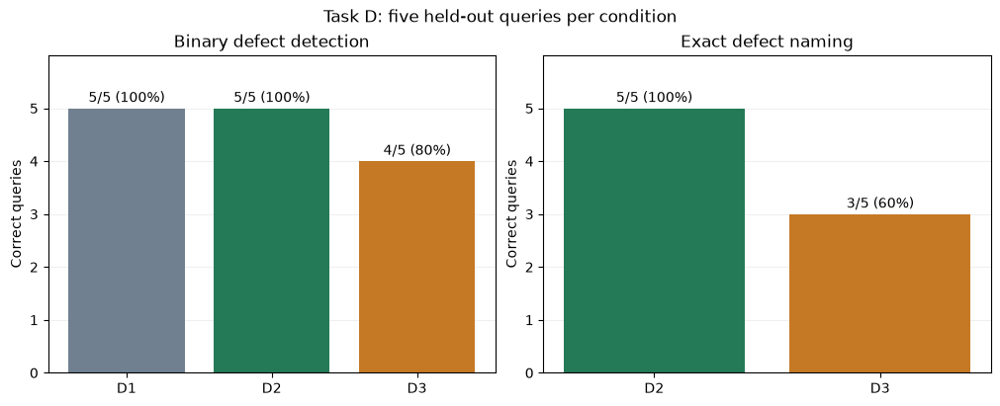

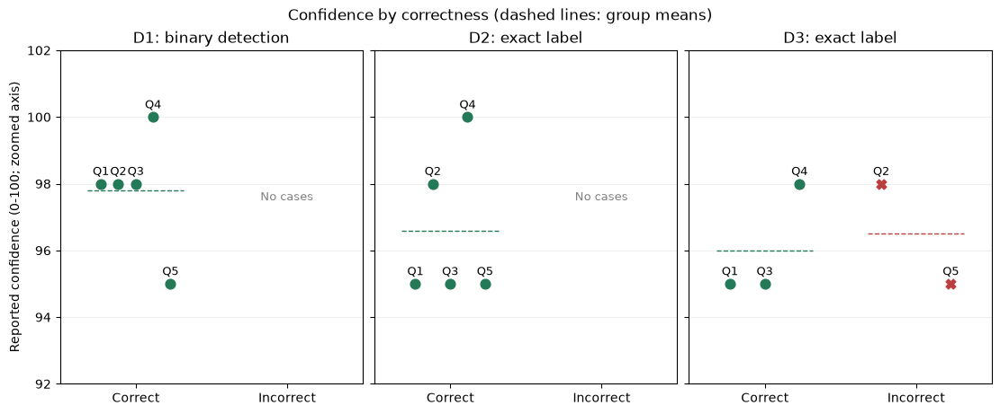

Saved four CSV tables, two figures, and analysis metadata to c:\Users\Matthew\Desktop\Y4S1\CS4243 Lab 1\code\student_files\task_d\analysis


In [25]:
#[AI-CODE] [HUMAN-CHECK]

confidence_summary = []
for condition in CONDITIONS:
    for criterion in ("binary_correct", "exact_label_correct"):
        for correct in (True, False):
            values = [r["confidence"] for r in scored_rows
                      if r["condition"] == condition and r[criterion] == correct]
            confidence_summary.append({
                "condition": condition, "criterion": criterion,
                "correct": correct, "count": len(values),
                "mean_confidence": round(float(np.mean(values)), 2) if values else "N/A",
                "min_confidence": min(values) if values else "N/A",
                "max_confidence": max(values) if values else "N/A",
            })
write_csv("confidence_summary.csv", confidence_summary)
primary_criterion = {"D1": "binary_correct", "D2": "exact_label_correct", "D3": "exact_label_correct"}
primary_summary = [r for r in confidence_summary if r["criterion"] == primary_criterion[r["condition"]]]
show_table(primary_summary, [("condition", "Condition"), ("criterion", "Correctness criterion"),
    ("correct", "Correct?"), ("count", "Count"), ("mean_confidence", "Mean confidence"),
    ("min_confidence", "Minimum"), ("max_confidence", "Maximum")])

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, conditions, metric, title in (
    (axes[0], CONDITIONS, "binary_correct", "Binary defect detection"),
    (axes[1], ("D2", "D3"), "exact_label_correct", "Exact defect naming"),
):
    totals = [next(r for r in condition_summary if r["condition"] == condition) for condition in conditions]
    bars = ax.bar(conditions, [r[metric] for r in totals], color=[{"D1": "#708090", "D2": "#247a56", "D3": "#c57924"}[c] for c in conditions])
    for bar, row in zip(bars, totals):
        ax.text(bar.get_x()+bar.get_width()/2, row[metric]+0.12,
                f"{row[metric]}/{row['n']} ({row[metric]/row['n']:.0%})", ha="center")
    ax.set(title=title, ylabel="Correct queries", ylim=(0, len(query_order)+1))
    ax.set_yticks(range(len(query_order)+1))
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle("Task D: five held-out queries per condition")
fig.savefig(ANALYSIS_DIR / "task_d_outcomes.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(11, 4.5), sharey=True, layout="constrained")
minimum = min(r["confidence"] for r in scored_rows)
maximum = max(r["confidence"] for r in scored_rows)
for ax, condition in zip(axes, CONDITIONS):
    criterion = primary_criterion[condition]
    for correct, position, color, marker in ((True, 0, "#247a56", "o"), (False, 1, "#ba3e3e", "X")):
        group = [r for r in scored_rows if r["condition"] == condition and r[criterion] == correct]
        offsets = np.linspace(-0.23, 0.23, len(group)) if len(group) > 1 else [0]
        for offset, row in zip(offsets, group):
            ax.scatter(position+offset, row["confidence"], color=color, marker=marker, s=60, zorder=3)
            ax.annotate(row["query_id"], (position+offset, row["confidence"]),
                        xytext=(0, 7), textcoords="offset points", ha="center", fontsize=9)
        if group:
            mean = float(np.mean([r["confidence"] for r in group]))
            ax.hlines(mean, position-0.32, position+0.32, color=color, linestyle="--", linewidth=1)
        else:
            ax.text(position, (minimum+maximum)/2, "No cases", ha="center", color="gray", fontsize=9)
    label = "binary detection" if condition == "D1" else "exact label"
    ax.set(title=f"{condition}: {label}", xlim=(-0.5, 1.5), ylim=(max(0, minimum-3), maximum+2))
    ax.set_xticks([0, 1], ["Correct", "Incorrect"])
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylabel("Reported confidence (0-100; zoomed axis)")
fig.suptitle("Confidence by correctness (dashed lines: group means)")
fig.savefig(ANALYSIS_DIR / "task_d_confidence.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

assert hashlib.sha256(LOG_PATH.read_bytes()).hexdigest() == log_hash, "Original predictions changed during analysis."
(ANALYSIS_DIR / "analysis_metadata.json").write_text(json.dumps({
    "prediction_csv": str(LOG_PATH.relative_to(ROOT)), "prediction_sha256": log_hash,
    "recorded_run_metadata": metadata, "n_predictions": len(scored_rows),
    "D1_policy": "binary discovery primary; literal exact names diagnostic; no alias mapping",
    "confidence_policy": "descriptive joint decision/name confidence; not a calibration test",
}, indent=2)+"\n", encoding="utf-8")
print(f"Saved four CSV tables, two figures, and analysis metadata to {ANALYSIS_DIR}")